#### **Imports**

In [1]:
import torch
import torch.nn as nn
import torchvision.transforms.functional as FT
import torch.nn.functional as F
import rasterio
import numpy as np
import matplotlib.pyplot as plt
import csv
import random
import json

from PIL import Image
from pathlib import Path
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.models.segmentation.fcn import FCNHead
from use_croma import PretrainedCROMA

In [2]:
from helper import load_split_paths, prepare_sample, Sen1Floods11Dataset, CROMAFloodSegmentation
from helper import IGNORE_INDEX, CROP_SIZE

#### **First things first**


In [3]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

pretrained_path = "pretrained/CROMA_large.pt"

path_to_the_dataset = "dataset/sen1floods11_hand_labeled_only/HandLabeled/"

path_to_the_dataset_index = "dataset/sen1floods11_hand_labeled_only/flood_handlabeled/"

path_to_X = path_to_the_dataset + "S1Hand/"

path_to_Y = path_to_the_dataset + "LabelHand/"

path_to_train_csv = path_to_the_dataset_index + "flood_train_data.csv"

path_to_val_csv = path_to_the_dataset_index + "flood_valid_data.csv"

path_to_test_csv = path_to_the_dataset_index + "flood_test_data.csv"
path_to_test_bolivia_csv = path_to_the_dataset_index + "flood_bolivia_data.csv"

print(device)

cuda


In [4]:
CROP_SIZE = 120
IGNORE_INDEX = 255

#### **Functions**

In [5]:
def preprocess_train(data):
    """
    Normalize the complete image,
    extract a random 120x120 crop,
    and apply synchronized random flips.
    """

    image, mask = prepare_sample(data)

    H, W = image.shape[-2:]

    assert H >= CROP_SIZE and W >= CROP_SIZE

    # Random crop coordinates
    top = torch.randint(
        0, H - CROP_SIZE + 1, (1,)
    ).item()

    left = torch.randint(
        0, W - CROP_SIZE + 1, (1,)
    ).item()

    # Same crop for image and ground-truth mask
    image = image[
        :, top:top + CROP_SIZE, left:left + CROP_SIZE
    ]

    mask = mask[
        top:top + CROP_SIZE, left:left + CROP_SIZE
    ]

    # Random horizontal flip
    if torch.rand(()) < 0.5:
        image = image.flip(-1)
        mask = mask.flip(-1)

    # Random vertical flip
    if torch.rand(()) < 0.5:
        image = image.flip(-2)
        mask = mask.flip(-2)

    return image, mask


## Note here mIoU is not being computed!
def preprocess_eval(data):
   
    return prepare_sample(data)

#### Creating datasets

In [6]:
train_data = load_split_paths(path_to_train_csv, path_to_X, path_to_Y)
val_data = load_split_paths(path_to_val_csv, path_to_X, path_to_Y)

In [7]:
print(f"Train samples: {len(train_data)}")
print(f"Validation samples: {len(val_data)}")

Train samples: 252
Validation samples: 89


In [8]:
print(train_data[0])

(WindowsPath('dataset/sen1floods11_hand_labeled_only/HandLabeled/S1Hand/Ghana_103272_S1Hand.tif'), WindowsPath('dataset/sen1floods11_hand_labeled_only/HandLabeled/LabelHand/Ghana_103272_LabelHand.tif'))


In [9]:
train_dataset = Sen1Floods11Dataset(
    data_list=train_data,
    preprocess_func=preprocess_train
)

valid_dataset = Sen1Floods11Dataset(
    data_list=val_data,
    preprocess_func=preprocess_eval
)

#### Creating DataLoaders

In [10]:
train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

# Training batch checks

images, masks = next(iter(train_loader))

print("Training images:", images.shape)
print("Training masks:", masks.shape)

print("Image min:", images.min().item())
print("Image max:", images.max().item())

print("Water pixels:", (masks == 1).sum().item())
print("Non-water pixels:", (masks == 0).sum().item())
print("Ignored pixels:", (masks == IGNORE_INDEX).sum().item())

assert torch.isfinite(images).all()

assert set(torch.unique(masks).tolist()).issubset(
    {0, 1, IGNORE_INDEX}
)

# Validation batch checks

val_images, val_masks = next(iter(valid_loader))

print("-" * 40)
print("Validation images:", val_images.shape)
print("Validation masks:", val_masks.shape)

Training images: torch.Size([16, 2, 120, 120])
Training masks: torch.Size([16, 120, 120])
Image min: 0.0
Image max: 1.0
Water pixels: 46455
Non-water pixels: 164404
Ignored pixels: 19541
----------------------------------------
Validation images: torch.Size([1, 2, 512, 512])
Validation masks: torch.Size([1, 512, 512])


##### Loading CROMA

In [11]:
croma = PretrainedCROMA(pretrained_path= pretrained_path, 
                        size='large', 
                        modality='SAR', 
                        image_resolution=120)

croma = croma.to(device)

Initializing SAR encoder


In [12]:
croma.requires_grad_(False) # Freeze the weights of CROMA
croma.eval()

PretrainedCROMA(
  (s1_encoder): ViT(
    (linear_input): Linear(in_features=128, out_features=1024, bias=True)
    (transformer): BaseTransformer(
      (layers): ModuleList(
        (0-11): 12 x ModuleList(
          (0): Attention(
            (to_qkv): Linear(in_features=1024, out_features=3072, bias=False)
            (to_out): Linear(in_features=1024, out_features=1024, bias=True)
            (input_norm): LayerNorm((1024,), eps=1e-05, elementwise_affine=True, bias=True)
            (dropout): Dropout(p=0.0, inplace=False)
          )
          (1): FFN(
            (net): Sequential(
              (0): Linear(in_features=1024, out_features=4096, bias=True)
              (1): GELU(approximate='none')
              (2): Dropout(p=0.0, inplace=False)
              (3): Linear(in_features=4096, out_features=1024, bias=True)
            )
            (input_norm): LayerNorm((1024,), eps=1e-05, elementwise_affine=True, bias=True)
          )
        )
      )
      (norm_out): LayerNo

### Creating the head

In [13]:
head = FCNHead(in_channels=1024, channels=2)

head[1] = nn.GroupNorm(
    num_groups=16,
    num_channels=256
)

head = head.to(device)

In [14]:
model = CROMAFloodSegmentation(croma, head).to(device)

In [15]:
LR = 5e-4

class_weights = torch.tensor(
    [1.0, 8.0],
    dtype=torch.float32,
    device=device
)

criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    ignore_index=IGNORE_INDEX
)

optimizer = torch.optim.AdamW(
    model.head.parameters(),
    lr=LR,
    weight_decay=1e-2
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
    optimizer,
    T_0=len(train_loader) * 10,
    T_mult=2,
    eta_min=0
)

In [16]:
def train_one_epoch(model, train_loader, optimizer, criterion, device):

    model.train()

    total_loss = 0.0
    total_weight = 0

    for images, masks in train_loader:

        # Move batch to GPU
        images = images.to(device)
        masks = masks.to(device)

        valid = masks != IGNORE_INDEX

        if not valid.any():
            continue

        # Reset previous gradients
        optimizer.zero_grad(set_to_none=True)

        # Forward pass
        logits = model(images)

        # Compute segmentation loss
        loss = criterion(logits, masks)

        # Backpropagation
        loss.backward()

        # Update FCN head weights
        optimizer.step()
        
        # Scheduler step
        scheduler.step()
        
        # Correct denominator of the weighted mean
        batch_weight = criterion.weight[masks[valid]].sum().item()

        total_loss += loss.item() * batch_weight
        total_weight += batch_weight

    if total_weight == 0:
        raise RuntimeError("No valid training pixels.")

    return total_loss / total_weight

In [17]:
@torch.inference_mode()
def sliding_window_logits(
    model,
    image,
    device,
    tile_size=120,
    stride=60,
    tile_batch_size=8
):
    """
    Predict segmentation logits for one complete image.

    Parameters
    ----------
    model:
        Frozen CROMA + trained FCN head.

    image:
        Tensor [2, H, W], already normalized.

    device:
        CUDA or CPU.

    tile_size:
        Spatial size of each CROMA input (120).

    stride:
        Distance between consecutive windows (60 = 50% overlap).

    tile_batch_size:
        Number of windows processed simultaneously.

    Returns
    -------
    logits:
        Tensor [2, H, W] on CPU.
    """

    model.eval()

    C, H, W = image.shape

    assert C == 2
    assert H >= tile_size and W >= tile_size
    assert 0 < stride <= tile_size

    # Generate starting positions along one dimension
    def get_starts(length):
        starts = list(
            range(0, length - tile_size + 1, stride)
        )

        # Ensure the final window reaches the image boundary
        if starts[-1] != length - tile_size:
            starts.append(length - tile_size)

        return starts

    # All window coordinates
    positions = [
        (top, left)
        for top in get_starts(H)
        for left in get_starts(W)
    ]

    # Accumulate predictions and coverage counts
    logits_sum = torch.zeros((2, H, W), dtype=torch.float32)
    counts = torch.zeros((H, W), dtype=torch.float32)

    # Process windows in batches
    for start in range(0, len(positions), tile_batch_size):

        batch_positions = positions[start:start + tile_batch_size]

        # Extract tiles
        tiles = torch.stack([
            image[:, top:top + tile_size, left:left + tile_size]
            for top, left in batch_positions
        ])

        tiles = tiles.to(device)

        # Run frozen CROMA + FCN head
        outputs = model(tiles).cpu()

        # Place tile predictions back into the full image
        for (top, left), logits in zip(batch_positions, outputs):

            logits_sum[
                :, top:top + tile_size, left:left + tile_size
            ] += logits

            counts[
                top:top + tile_size, left:left + tile_size
            ] += 1

    assert (counts > 0).all(), "Some pixels were not covered."

    # Average logits wherever windows overlap
    return logits_sum / counts.unsqueeze(0)


import torch.nn.functional as F

@torch.inference_mode()
def validate(model, valid_loader, criterion, device):

    model.eval()

    total_loss = 0.0
    total_valid_pixels = 0

    TP = FP = FN = TN = 0

    for images, masks in valid_loader:

        # Process every complete image in the batch.
        for image, mask in zip(images, masks):
            mask = mask.cpu()
            
            
            valid = mask != IGNORE_INDEX

            if not valid.any():
                continue

            # Reconstruct logits using overlapping windows.
            logits = sliding_window_logits(
                model,
                image,
                device,
                tile_size=CROP_SIZE,
                stride=CROP_SIZE // 2,
                tile_batch_size=8
            )
            
            logits_device = logits.unsqueeze(0).to(device)
            mask_device = mask.unsqueeze(0).to(device=device, dtype=torch.long)

            loss = criterion(logits_device, mask_device)

            image_weight = criterion.weight[
                mask_device[mask_device != IGNORE_INDEX]
            ].sum().item()

            total_loss += loss.item() * image_weight
            total_valid_pixels += image_weight

            prediction = logits.argmax(dim=0)

            TP += ((prediction == 1) & (mask == 1) & valid).sum().item()
            FP += ((prediction == 1) & (mask == 0) & valid).sum().item()
            FN += ((prediction == 0) & (mask == 1) & valid).sum().item()
            TN += ((prediction == 0) & (mask == 0) & valid).sum().item()

    if total_valid_pixels == 0:
        raise RuntimeError("No valid validation pixels.")

    val_loss = total_loss / total_valid_pixels

    water_iou = TP / (TP + FP + FN) if TP + FP + FN else float("nan")
    nonwater_iou = TN / (TN + FP + FN) if TN + FP + FN else float("nan")
    miou = (water_iou + nonwater_iou) / 2

    return {
        "val_loss": val_loss,
        "water_iou": water_iou,
        "miou": miou
    }

In [18]:
metrics = validate(model, valid_loader, criterion, device)

print(f"Validation Loss:      {metrics['val_loss']:.4f}")
print(f"Validation Water IoU: {metrics['water_iou']:.4f}")
print(f"Validation mIoU:      {metrics['miou']:.4f}")

Validation Loss:      0.6735
Validation Water IoU: 0.1139
Validation mIoU:      0.0794


In [ ]:
'''


EPOCHS = 100
best_val_iou = -1.0
best_epoch = None

model_name = "croma_best_head_weighted_loss_with_scheduler_2.pt"

Path("checkpoints").mkdir(exist_ok=True)

history = {
    "train_loss": [],
    "val_loss": [],
    "val_water_iou": [],
    "val_miou": []
}

for epoch in range(EPOCHS):

    train_loss = train_one_epoch(
        model=model,
        criterion=criterion,
        train_loader=train_loader,
        device=device,
        optimizer=optimizer
    )

    metrics = validate(
        model=model,
        valid_loader=valid_loader,
        criterion=criterion,
        device=device
    )

    val_loss = metrics["val_loss"]
    val_water_iou = metrics["water_iou"]
    val_miou = metrics["miou"]

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_water_iou"].append(val_water_iou)
    history["val_miou"].append(val_miou)

  
    if val_water_iou > best_val_iou:

        best_val_iou = val_water_iou
        best_epoch = epoch + 1

        torch.save(
            {
                "epoch": best_epoch,
                "head_state_dict": model.head.state_dict(),
                "best_val_water_iou": best_val_iou,
                "val_miou": val_miou,
                "val_loss": val_loss,
            },
            "checkpoints/" + model_name
        )
    
    with open("checkpoints/croma_training_history.json", "w") as f:
        json.dump({
            "epochs_completed": epoch + 1,
            "best_epoch": best_epoch,
            "best_val_water_iou": best_val_iou,
            "history": history
        }, f, indent=4)

 
    print(
        f"Epoch [{epoch+1:02d}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Water IoU: {val_water_iou:.4f} | "
        f"mIoU: {val_miou:.4f}"
    )

print(
    f"\nBest model: Epoch {best_epoch}, "
    f"Water IoU = {best_val_iou:.4f}"
)

'''

Epoch [01/100] | Train Loss: 0.4873 | Val Loss: 0.3275 | Water IoU: 0.4459 | mIoU: 0.6590
Epoch [02/100] | Train Loss: 0.3945 | Val Loss: 0.3058 | Water IoU: 0.5052 | mIoU: 0.7016
Epoch [03/100] | Train Loss: 0.3461 | Val Loss: 0.2766 | Water IoU: 0.5047 | mIoU: 0.6996
Epoch [04/100] | Train Loss: 0.2980 | Val Loss: 0.2494 | Water IoU: 0.4957 | mIoU: 0.6912
Epoch [05/100] | Train Loss: 0.2981 | Val Loss: 0.2496 | Water IoU: 0.4969 | mIoU: 0.6918
Epoch [06/100] | Train Loss: 0.2743 | Val Loss: 0.2478 | Water IoU: 0.5374 | mIoU: 0.7226
Epoch [07/100] | Train Loss: 0.2617 | Val Loss: 0.2454 | Water IoU: 0.5518 | mIoU: 0.7331
Epoch [08/100] | Train Loss: 0.3029 | Val Loss: 0.2418 | Water IoU: 0.5366 | mIoU: 0.7219
Epoch [09/100] | Train Loss: 0.2913 | Val Loss: 0.2419 | Water IoU: 0.5225 | mIoU: 0.7115
Epoch [10/100] | Train Loss: 0.2531 | Val Loss: 0.2418 | Water IoU: 0.5237 | mIoU: 0.7123
Epoch [11/100] | Train Loss: 0.2582 | Val Loss: 0.3170 | Water IoU: 0.6116 | mIoU: 0.7777
Epoch [12/

In [20]:
print(
    "CROMA trainable parameters:",
    sum(p.numel() for p in model.croma.parameters()
        if p.requires_grad)
)

print(
    "Head trainable parameters:",
    sum(p.numel() for p in model.head.parameters()
        if p.requires_grad)
)

CROMA trainable parameters: 0
Head trainable parameters: 2360322


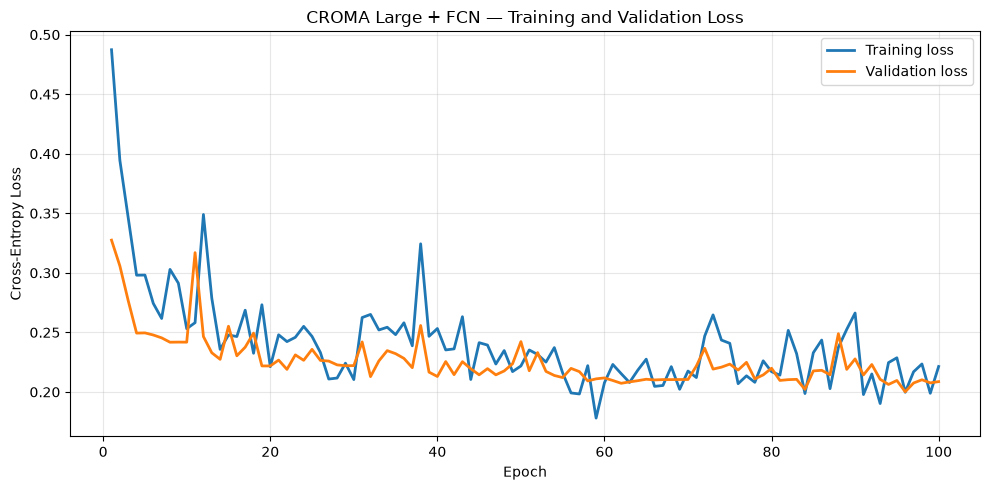

In [21]:
epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(10, 5))

plt.plot(
    epochs,
    history["train_loss"],
    label="Training loss",
    linewidth=2
)

plt.plot(
    epochs,
    history["val_loss"],
    label="Validation loss",
    linewidth=2
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("CROMA Large + FCN — Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

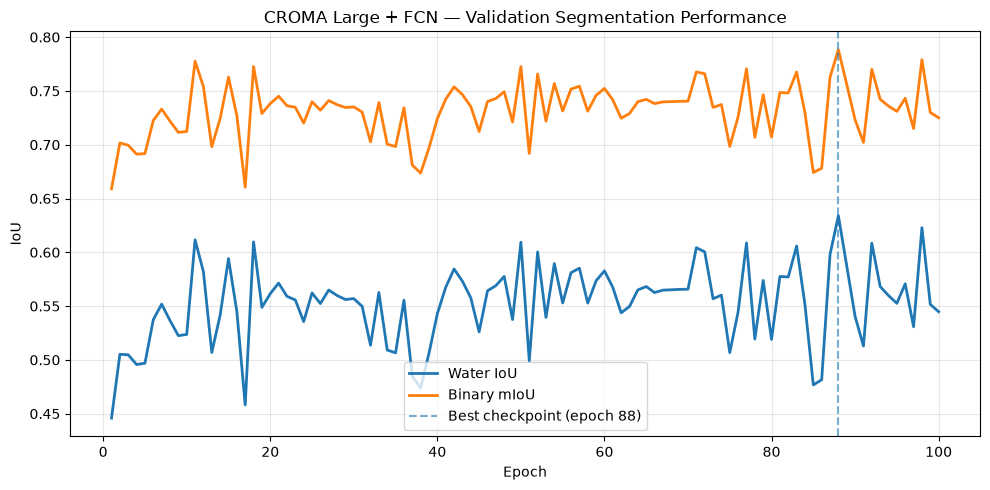

In [22]:
plt.figure(figsize=(10, 5))

plt.plot(
    epochs,
    history["val_water_iou"],
    label="Water IoU",
    linewidth=2
)

plt.plot(
    epochs,
    history["val_miou"],
    label="Binary mIoU",
    linewidth=2
)

plt.axvline(
    best_epoch,
    linestyle="--",
    alpha=0.6,
    label=f"Best checkpoint (epoch {best_epoch})"
)

plt.xlabel("Epoch")
plt.ylabel("IoU")
plt.title("CROMA Large + FCN — Validation Segmentation Performance")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()